<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_008_redes_neuronales_artificiales/02_MLP_EZ_Keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neuronales Artificiales - Multicapa

En la implementación Keras:

* Función de Activación Logística: 0 a 1
* Función de Activación Tanh: -1 a 1

En este ejemplo usaremos los datos de diferenciación niños/adultos usando estatura y peso, y aplicaremos distancia euclidiana.

Text(0, 0.5, 'Peso en kilogramos')

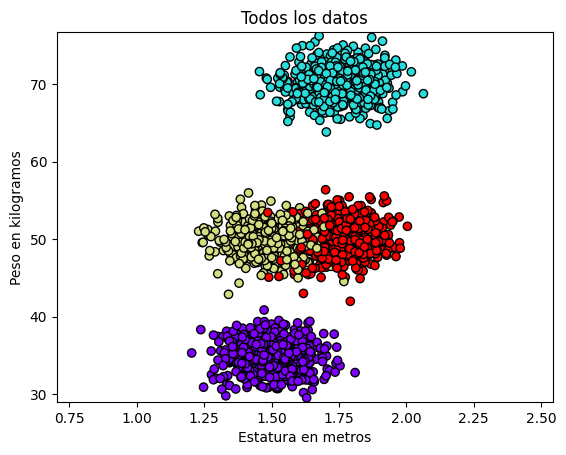

In [1]:
from sklearn.datasets import make_blobs
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

X, y = make_blobs(n_samples=[500,500,500,500],
                  n_features = 4,
                  centers=[[1.50,35],[1.75,70],[1.50,50],[1.75,50]],
                  cluster_std = [[0.1,2],[0.1,2],[0.1,2],[0.1,2]],
                  random_state=1970)
#y = y+1.0
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
h = 0.02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                      np.arange(y_min, y_max, h))

# just plot the dataset first
cm = plt.cm.rainbow
cm_bright = cm
#cm_bright = ListedColormap(['#FF0000', '#0000FF','#0FF000', '#000000'])
ax = plt.figure()
plt.title("Todos los datos")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")


El ejemplo lo basaremos en datos simulados que representan\
una población de personas de género masculino\
niños y adultos, y se tienen dos características de ellos: estatura y peso

Dado que las escalas de peso y estaturas son muy diferentes
(dos ordenes de magnitud)
Antes de aplicar el clasificador, debemos llevarlas
a la misma escala:
* Se resta la media
* Se divide por la desviación estándar


In [2]:
from sklearn import preprocessing
#X_estandarizada = X
X_estandarizada = preprocessing.scale(X)
X = X_estandarizada

Y volvemos a mostrar los datos ...

Text(0, 0.5, 'Peso en kilogramos')

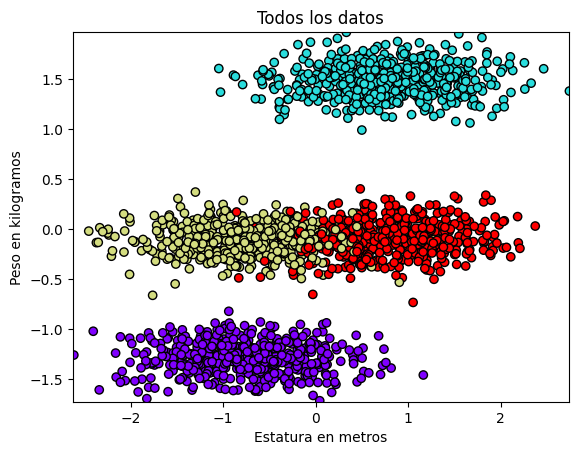

In [3]:
x_min, x_max = X[:, 0].min() - .01, X[:, 0].max() + .01
y_min, y_max = X[:, 1].min() - .01, X[:, 1].max() + .01
h = 0.02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                      np.arange(y_min, y_max, h))

# just plot the dataset first
#cm = plt.cm.RdBu
#cm_bright = ListedColormap(['#FF0000', '#0000FF','#0FF000', '#000000'])
ax = plt.figure()
plt.title("Todos los datos")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")

Ahora creamos los datos de prueba y entrenamiento

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = \
    train_test_split(X, y, test_size=0.33, random_state=1970)

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

cbez = EarlyStopping(monitor='accuracy',
                      min_delta=0.01,
                      mode='max',
                      patience=10,
                      )
model1 = Sequential()
model1.add(Input(shape=(2,)))
model1.add(Dense(4, activation='sigmoid'))#'sigmoid'))
model1.add(Dropout(0.25))
#model1.add(Dense(3, activation='relu'))
#model1.add(Dense(3, activation='relu'))
#model1.add(Dense(10, activation='relu'))
model1.add(Dense(4, activation='sigmoid'))
model1.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])
#%%

epk1 = 100
model1.fit(X_train,
           y_train,
           epochs=epk1,
           callbacks=[cbez],
           validation_split=0.2
           )
#%%
y_new = np.argmax(model1.predict(X_test),axis=1)
y_esperado = y_test
y_predicho = y_new

Epoch 1/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.2836 - loss: 1.4719 - val_accuracy: 0.2463 - val_loss: 1.4133
Epoch 2/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2593 - loss: 1.4341 - val_accuracy: 0.2463 - val_loss: 1.3763
Epoch 3/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2696 - loss: 1.3879 - val_accuracy: 0.2463 - val_loss: 1.3453
Epoch 4/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3358 - loss: 1.3482 - val_accuracy: 0.4664 - val_loss: 1.3171
Epoch 5/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3815 - loss: 1.3213 - val_accuracy: 0.4851 - val_loss: 1.2908
Epoch 6/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3535 - loss: 1.3118 - val_accuracy: 0.4888 - val_loss: 1.2668
Epoch 7/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3787 - loss: 1.2763 - val_accuracy: 0.4888 - val_loss: 1.2445
Epoch 8/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3881 - loss: 1.2518 - val_accuracy: 0.4888 - 

In [6]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_esperado,y_predicho))

0.9545454545454546


Como se puede ver, el sistema es capaz de clasificar\
correctamente mas del 96% de los datos de prueba

1564/1564 ━━━━━━━━━━━━━━━━━━━━ 2s 989us/step
(50034,)
(186, 269)


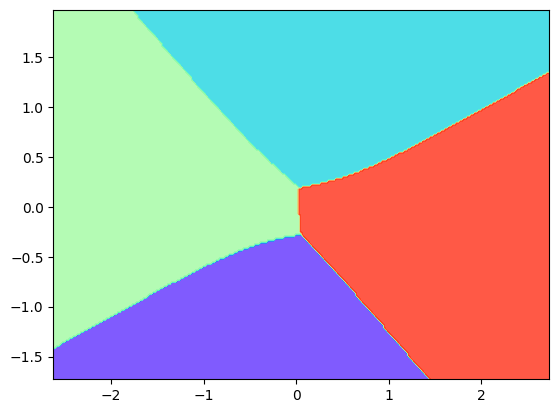

In [7]:
# ZT =clfANN.predict_proba(np.c_[xx.ravel(), yy.ravel()])
ZT = np.argmax(model1.predict(np.c_[xx.ravel(), yy.ravel()]),axis=1)
print(ZT.shape)
print(xx.shape)
# Put the result into a color plot
Z = ZT.reshape(xx.shape)
plt.figure()
plt.contourf(xx, yy, Z, cmap=cm, alpha=.8)

Y esto es lo que el sistema sabe